# 05 Causal mapping (experiment)

Extracts causal claims (cause node, actor attribution, target, edge type, evidence, confidence) from the answers with the causal-mapping codebook and prompt (`MaxNLP.py`), and compares them with a manual annotation sheet.

Cells tagged `api` call the LLM (OpenAI or Nebula) and were **not executed** for this repository. `dummy_data/` holds 12 synthetic citizen answers (plus 4 expert rows), random coding runs and random manual codings with the original file names. All results shown are meaningless.

In [1]:
# Folders. The original notebook read and wrote files in the project folder:
# DATA_DIR = OUT_DIR = "."
DATA_DIR = "dummy_data"   # synthetic example data shipped with this repo
OUT_DIR = "output"        # written by the notebook (gitignored)
import os; os.makedirs(OUT_DIR, exist_ok=True)

# ---- API switch -------------------------------------------------------------
# Cells starting with %%api call an external API (OpenAI, Nebula, Qualtrics, Eurostat, TypeSafe).
# RUN_API = False: these cells are skipped, so "Run All" makes no API calls and changes nothing on a server.
# RUN_API = True:  they run normally (needs the API keys; see README).
RUN_API = False
from IPython.core.magic import register_cell_magic
@register_cell_magic
def api(line, cell):
    if RUN_API:
        get_ipython().run_cell(cell)
    else:
        print("API cell skipped (RUN_API = False)")

In [2]:
import pandas as pd
import MaxNLP
import MaxNLP as causal_nlp
from pathlib import Path
from tqdm.auto import tqdm
import json
tqdm.pandas(desc="Applying")
%load_ext autoreload
%autoreload 2
    
from datetime import date
date_str = date.today().isoformat()

pd.set_option('display.max_colwidth', None)

In [3]:
df_t=pd.read_json(f"{DATA_DIR}/clean_df.json")
df_t=df_t[df_t["country"].isin(['Germany', 'France', 'Italy', 'Spain', 'Poland', 'Romania',
       'Netherlands', 'Belgium', 'Portugal', 'Czech Republic'])]
N_PER_COUNTRY = min(100, df_t["country"].value_counts().min())  # fixed: 100 per country, or fewer if a country has fewer answers (dummy data)
df_50 = df_t.groupby("country", group_keys=False).sample(n=N_PER_COUNTRY, random_state=42)


In [4]:
df_de=df_50[df_50["country"]=="Germany"]
df_nl=df_50[df_50["country"]=="Netherlands"]
df=df_de


In [5]:
#
#df=df[df.country.isin(["Germany","Netherlands"])].sample(10)


In [6]:
codebook_causal_mapping = Path("codebooks/2026-05-07 causal mapping codebook.md").read_text(encoding="utf-8")
PROMPTBOOK_INSTRUCTIONS =  Path("codebooks/2026-05-07 causal mapping prompt.md").read_text(encoding="utf-8")#

SYSTEM_PROMPT = (
    PROMPTBOOK_INSTRUCTIONS
    + "\n\n"
    + codebook_causal_mapping
).strip()


In [7]:


CAUSE_CODES = [
    "WAR_UKRAINE",
    "FAST_TRANSITION",
    "FOSSIL_DEPENDENCE",
    "IMPORT_CONCENTRATION",
    "NATURAL_DISASTERS",
    "EXT_SHOCKS",
    "PRICE_REGULATION_FAILURE",
    "NUCLEAR_PHASEOUT_REDUCED_PRODUCTION",
    "EU_SANCTIONS_RUSSIA",
    "EU_COORDINATION_FAILURE",
    "MARKET_SPECULATION",
    "MEDIA_SENSATIONALISM",
    "ABSTRACT_SOCIAL",
    "EU_ENERGY_CRISIS"
]

ACTOR_CODES = [
    "EU_POLITICS",
    "NATIONAL_POLITICS",
    "MARKET_ACTORS",
    "MEDIA_ACTORS",
    "RUSSIA",
    "OTHER_EXTERNAL_ACTORS",
    "UNSPECIFIED"
]

SCHEMA = causal_nlp.make_causal_schema(
    cause_codes=CAUSE_CODES,
    actor_codes=ACTOR_CODES
)


In [8]:
%%api
# Load the Nebula Client
from dotenv import load_dotenv
import openAI_key

client=MaxNLP.create_client(client="Nebula", openAI_key=openAI_key)
available_models = MaxNLP.get_nebula_models(client)

print(f"Models: {available_models}\n\n")


API cell skipped (RUN_API = False)


In [9]:
%%api
# added: %%api - this cell calls the LLM for every answer
import json
import re
from pathlib import Path
import pandas as pd
from tqdm import tqdm

tqdm.pandas()

outdir = Path("causal_coding_results")
outdir.mkdir(exist_ok=True)

all_run_dfs = []

for run in range(3,5):
    print(f"Starting run {run}...")

    results = df.progress_apply(
        lambda row: causal_nlp.code_one_response(
            text=row["QID8"],
            response_id=row.name,
            client=client,
            model="FAST.gpt-oss:120b",
            SYSTEM_PROMPT=SYSTEM_PROMPT,
            SCHEMA=SCHEMA,
            Temperature=0.1
        ),
        axis=1
    )

    run_df = pd.DataFrame(results.tolist()).copy()
    run_df["response_text"] = df["QID8"].values
    run_df["response_id"] = df.index
    run_df["run"] = run

    json_path = outdir / f"{date_str} results_run_{run}.json"
    run_df.to_json(json_path, orient="records", indent=2, force_ascii=False)

    all_run_dfs.append(run_df)

print("Done.")

API cell skipped (RUN_API = False)


In [10]:
from pathlib import Path
import pandas as pd

outdir = Path("causal_coding_results")
results_date = date_str  # date of the coding runs above
if not RUN_API:  # added: without API calls, read the synthetic example runs shipped in dummy_data
    outdir, results_date = Path(DATA_DIR) / "causal_coding_results", "2000-01-01"
run_dfs = {
    run: pd.read_json(outdir / f"{results_date} results_run_{run}.json").set_index("response_id")
    for run in range(5)
}

combined_df = pd.concat(run_dfs, names=["run", "response_id"]).sort_index()
combined_for_alpha = causal_nlp.flatten_claim_sets_for_alpha(combined_df)


In [11]:
import json
import pandas as pd

def first_mode(s):
    if s.map(lambda v: isinstance(v, (list, dict))).any():  # added: claim lists cannot be compared -> mode over their JSON text
        keys = s.map(lambda v: json.dumps(v, sort_keys=True, ensure_ascii=False))
        m = keys.mode(dropna=True)
        return json.loads(m.iloc[0]) if len(m) else pd.NA
    m = s.mode(dropna=True)
    return m.iloc[0] if len(m) else pd.NA

results_mode_df = (
    combined_df
    .groupby(level="response_id")
    .agg(first_mode)
)

In [12]:
for col in combined_for_alpha.columns:
    vals = pd.unique(combined_for_alpha[col].dropna())
    if len(vals) < 2:
        print(col, vals)

In [13]:
combined_for_alpha

has_causal_claim  cause_ABSTRACT_SOCIAL  \
run response_id                                            
0   2                           0                      0   
    3                           0                      0   
    4                           1                      0   
    5                           0                      0   
    6                           1                      0   
...                           ...                    ...   
4   13                          0                      0   
    14                          1                      1   
    15                          1                      0   
    16                          0                      0   
    17                          1                      0   

                 cause_EU_COORDINATION_FAILURE  cause_EU_SANCTIONS_RUSSIA  \
run response_id                                                             
0   2                                        0                          0   
    3                                        0                          0   
    4                                        0                          0   
    5                                        0                          0   
    6                                        0                          1   
...                                        ...                        ...   
4   13                                       0                          0   
    14                                       0                          0   
    15                                       0                          0   
    16                                       0                          0   
    17                                       0                          1   

                 cause_EXT_SHOCKS  cause_FAST_TRANSITION  \
run response_id                                            
0   2                           0                      0   
    3                           0                      0   
    4                           0                      0   
    5                           0                      0   
    6                           0                      0   
...                           ...                    ...   
4   13                          0                      0   
    14                          0                      0   
    15                          1                      1   
    16                          0                      0   
    17                          0                      0   

                 cause_FOSSIL_DEPENDENCE  cause_IMPORT_CONCENTRATION  \
run response_id                                                        
0   2                                  0                           0   
    3                                  0                           0   
    4                                  0                           1   
    5                                  0                           0   
    6                                  0                           0   
...                                  ...                         ...   
4   13                                 0                           0   
    14                                 0                           0   
    15                                 0                           0   
    16                                 0                           0   
    17                                 0                           0   

                 cause_MEDIA_SENSATIONALISM  cause_NATURAL_DISASTERS  ...  \
run response_id                                                       ...   
0   2                                     0                        0  ...   
    3                                     0                        0  ...   
    4                                     0                        0  ...   
    5                                     0                        0  ...   
    6                                     0           

In [14]:
alpha_results = MaxNLP.kripp_alpha_all_variables(combined_for_alpha, decimals=3)
alpha_results

,krippendorff_alpha,assessment
variable,,
has_causal_claim,1.000,reliable
actor_MARKET_ACTORS,1.000,reliable
actor_EU_POLITICS,1.000,reliable
target_FAST_TRANSITION,1.000,reliable
target_EXT_SHOCKS,1.000,reliable
target_EU_SANCTIONS_RUSSIA,1.000,reliable
target_EU_ENERGY_CRISIS,1.000,reliable
target_EU_COORDINATION_FAILURE,1.000,reliable
actor_UNSPECIFIED,1.000,reliable


In [15]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from collections import Counter

# -----------------------------
# 1. Expand claims into long format
# -----------------------------
claims_long = (
    results_mode_df.reset_index()[["response_id", "response_text", "claims", "has_causal_claim", "notes"]]
    .explode("claims")
    .reset_index(drop=True)
)

claims_long = claims_long[claims_long["claims"].notna()].copy()

claim_cols = pd.json_normalize(claims_long["claims"])
claims_long = pd.concat(
    [claims_long.drop(columns=["claims"]).reset_index(drop=True),
     claim_cols.reset_index(drop=True)],
    axis=1
)

claims_long = claims_long[claims_long["cause_node"].notna()].copy()

# optional readable labels
label_map = {
    "WAR_UKRAINE": "Russia's war on Ukraine",
    "FAST_TRANSITION": "Too-fast energy transition",
    "FOSSIL_DEPENDENCE": "Dependence on fossil fuels",
    "IMPORT_CONCENTRATION": "Concentrated import dependency",
    "NATURAL_DISASTERS": "Natural disasters",
    "EXT_SHOCKS": "External shocks / technical failures",
    "PRICE_REGULATION_FAILURE": "Insufficient price regulation",
    "NUCLEAR_PHASEOUT_REDUCED_PRODUCTION": "Nuclear phase-out / reduced production",
    "EU_SANCTIONS_RUSSIA": "Sanctions against Russia",
    "EU_COORDINATION_FAILURE": "EU coordination failure",
    "MARKET_SPECULATION": "Market speculation / profiteering",
    "MEDIA_SENSATIONALISM": "Media sensationalism",
    "ABSTRACT_SOCIAL": "Abstract social / ideological causes",
    "EU_ENERGY_CRISIS": "EU energy crisis",
    "EU_POLITICS": "EU political actors",
    "NATIONAL_POLITICS": "National political actors",
    "MARKET_ACTORS": "Market actors",
    "MEDIA_ACTORS": "Media actors",
    "RUSSIA": "Russia",
    "OTHER_EXTERNAL_ACTORS": "Other external actors",
    "UNSPECIFIED": "Unspecified actor"
}

# -----------------------------
# 2. Aggregate edge tables
# -----------------------------
edge_counts = (
    claims_long
    .groupby(["cause_node", "target", "edge_type"], dropna=False)
    .agg(
        weight=("response_id", "size"),
        n_responses=("response_id", "nunique")
    )
    .reset_index()
)

main_edges = (
    edge_counts
    .sort_values(["cause_node", "target", "weight", "n_responses"], ascending=[True, True, False, False])
    .drop_duplicates(["cause_node", "target"])
    .rename(columns={"weight": "majority_weight", "n_responses": "majority_n_responses"})
)

total_edges = (
    claims_long
    .groupby(["cause_node", "target"], dropna=False)
    .agg(
        total_weight=("response_id", "size"),
        total_n_responses=("response_id", "nunique")
    )
    .reset_index()
)

main_edges = main_edges.merge(total_edges, on=["cause_node", "target"], how="left")

actor_edges = (
    claims_long
    .groupby(["actor_attribution", "cause_node"], dropna=False)
    .agg(
        weight=("response_id", "size"),
        n_responses=("response_id", "nunique")
    )
    .reset_index()
)

# node mention frequencies
source_nodes = claims_long[["cause_node", "response_id"]].rename(columns={"cause_node": "node"})
target_nodes = claims_long[["target", "response_id"]].rename(columns={"target": "node"})
actor_nodes = claims_long[["actor_attribution", "response_id"]].rename(columns={"actor_attribution": "node"})

main_node_freq = (
    pd.concat([source_nodes, target_nodes], ignore_index=True)
    .groupby("node")
    .agg(mentions=("response_id", "size"), n_responses=("response_id", "nunique"))
    .reset_index()
)

actor_node_freq = (
    pd.concat([actor_nodes, source_nodes], ignore_index=True)
    .groupby("node")
    .agg(mentions=("response_id", "size"), n_responses=("response_id", "nunique"))
    .reset_index()
)

main_node_freq_dict = main_node_freq.set_index("node").to_dict("index")
actor_node_freq_dict = actor_node_freq.set_index("node").to_dict("index")



# -----------------------------
# 3. Build NetworkX graphs
# -----------------------------

G_main = nx.DiGraph()
for _, row in main_edges.iterrows():
    G_main.add_edge(
        row["cause_node"],
        row["target"],
        edge_type=row["edge_type"],
        weight=int(row["total_weight"]),
        n_responses=int(row["total_n_responses"]),
        majority_weight=int(row["majority_weight"]),
        majority_n_responses=int(row["majority_n_responses"])
    )
for node in G_main.nodes():
    attrs = main_node_freq_dict.get(node, {"mentions": 0, "n_responses": 0})
    G_main.nodes[node]["mentions"] = int(attrs["mentions"])
    G_main.nodes[node]["n_responses"] = int(attrs["n_responses"])
    G_main.nodes[node]["label"] = label_map.get(node, node)
    G_main.nodes[node]["node_group"] = "outcome" if node == "EU_ENERGY_CRISIS" else "cause"

G_actor = nx.DiGraph()
for _, row in actor_edges.iterrows():
    G_actor.add_edge(
        row["actor_attribution"],
        row["cause_node"],
        relation="ATTRIBUTES_BLAME",
        weight=int(row["weight"]),
        n_responses=int(row["n_responses"])
    )

actor_codes = {
    "EU_POLITICS", "NATIONAL_POLITICS", "MARKET_ACTORS", "MEDIA_ACTORS",
    "RUSSIA", "OTHER_EXTERNAL_ACTORS", "UNSPECIFIED"
}

for node in G_actor.nodes():
    attrs = actor_node_freq_dict.get(node, {"mentions": 0, "n_responses": 0})
    G_actor.nodes[node]["mentions"] = int(attrs["mentions"])
    G_actor.nodes[node]["n_responses"] = int(attrs["n_responses"])
    G_actor.nodes[node]["label"] = label_map.get(node, node)
    G_actor.nodes[node]["node_group"] = "actor" if node in actor_codes else "cause"


nx.write_gexf(G_main, f"{OUT_DIR}/energy_crisis_main_graph.gexf")  # fixed: OUT_DIR
nx.write_gexf(G_actor, f"{OUT_DIR}/energy_crisis_actor_graph.gexf")  # fixed: OUT_DIR



In [16]:
main_edges

,cause_node,target,edge_type,majority_weight,majority_n_responses,total_weight,total_n_responses
0,ABSTRACT_SOCIAL,EU_ENERGY_CRISIS,CAUSES,1,1,1,1
1,ABSTRACT_SOCIAL,WAR_UKRAINE,CAUSES,1,1,1,1
2,EU_SANCTIONS_RUSSIA,EU_COORDINATION_FAILURE,CAUSES,1,1,1,1
3,EU_SANCTIONS_RUSSIA,EU_ENERGY_CRISIS,WORSENS,1,1,1,1
4,EU_SANCTIONS_RUSSIA,NATURAL_DISASTERS,CAUSES,1,1,1,1
5,EXT_SHOCKS,EU_SANCTIONS_RUSSIA,CAUSES,1,1,1,1
6,EXT_SHOCKS,EXT_SHOCKS,CAUSES,1,1,1,1
7,FOSSIL_DEPENDENCE,EXT_SHOCKS,CAUSES,1,1,1,1
8,IMPORT_CONCENTRATION,EXT_SHOCKS,WORSENS,1,1,1,1
9,IMPORT_CONCENTRATION,FAST_TRANSITION,WORSENS,1,1,1,1


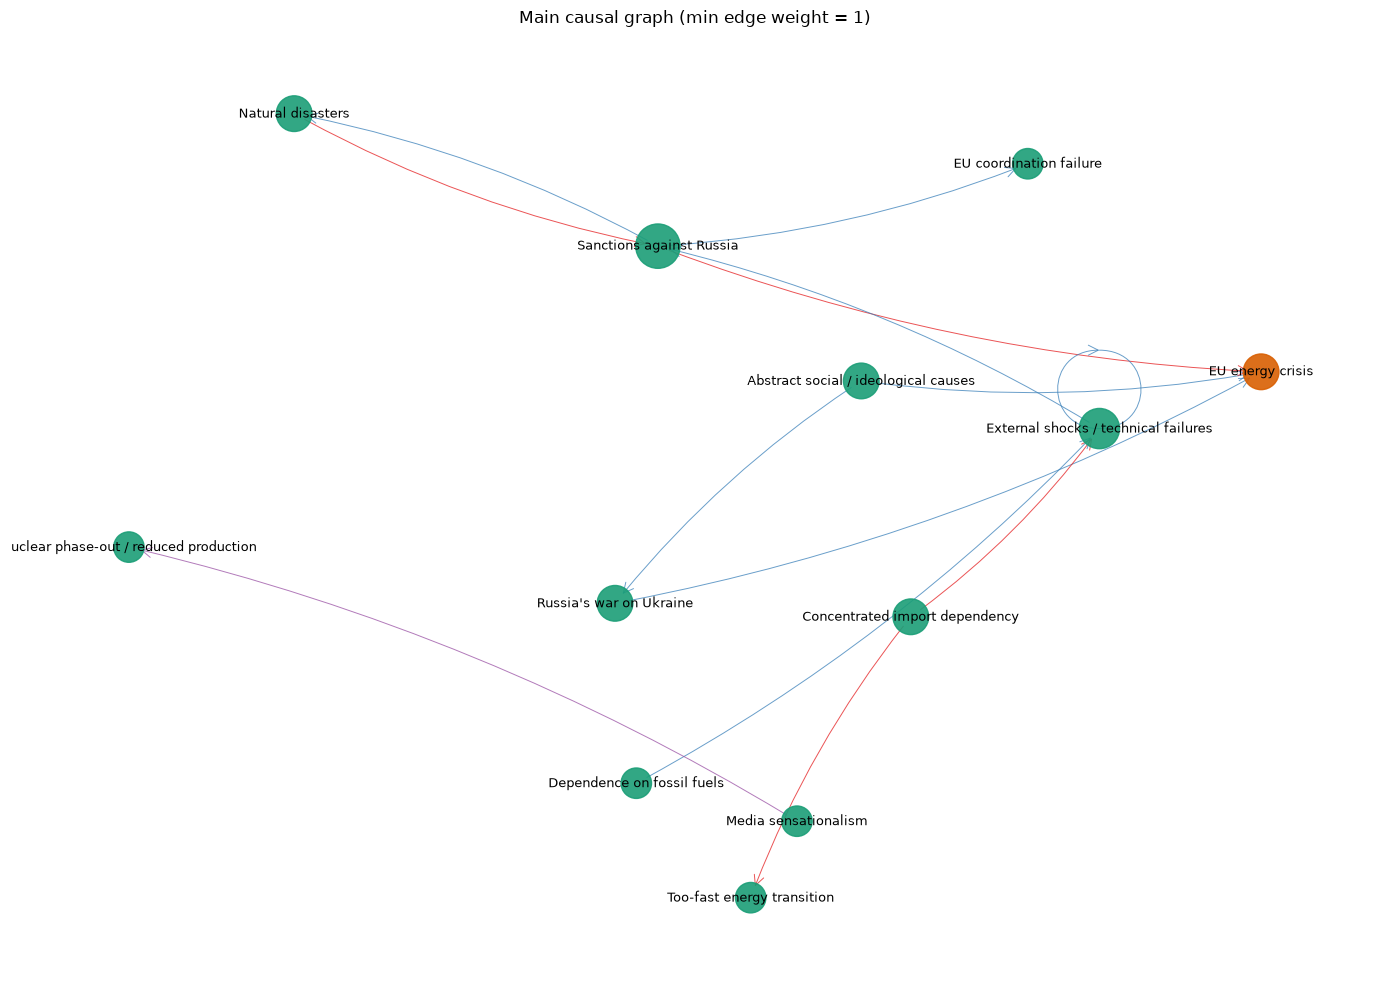

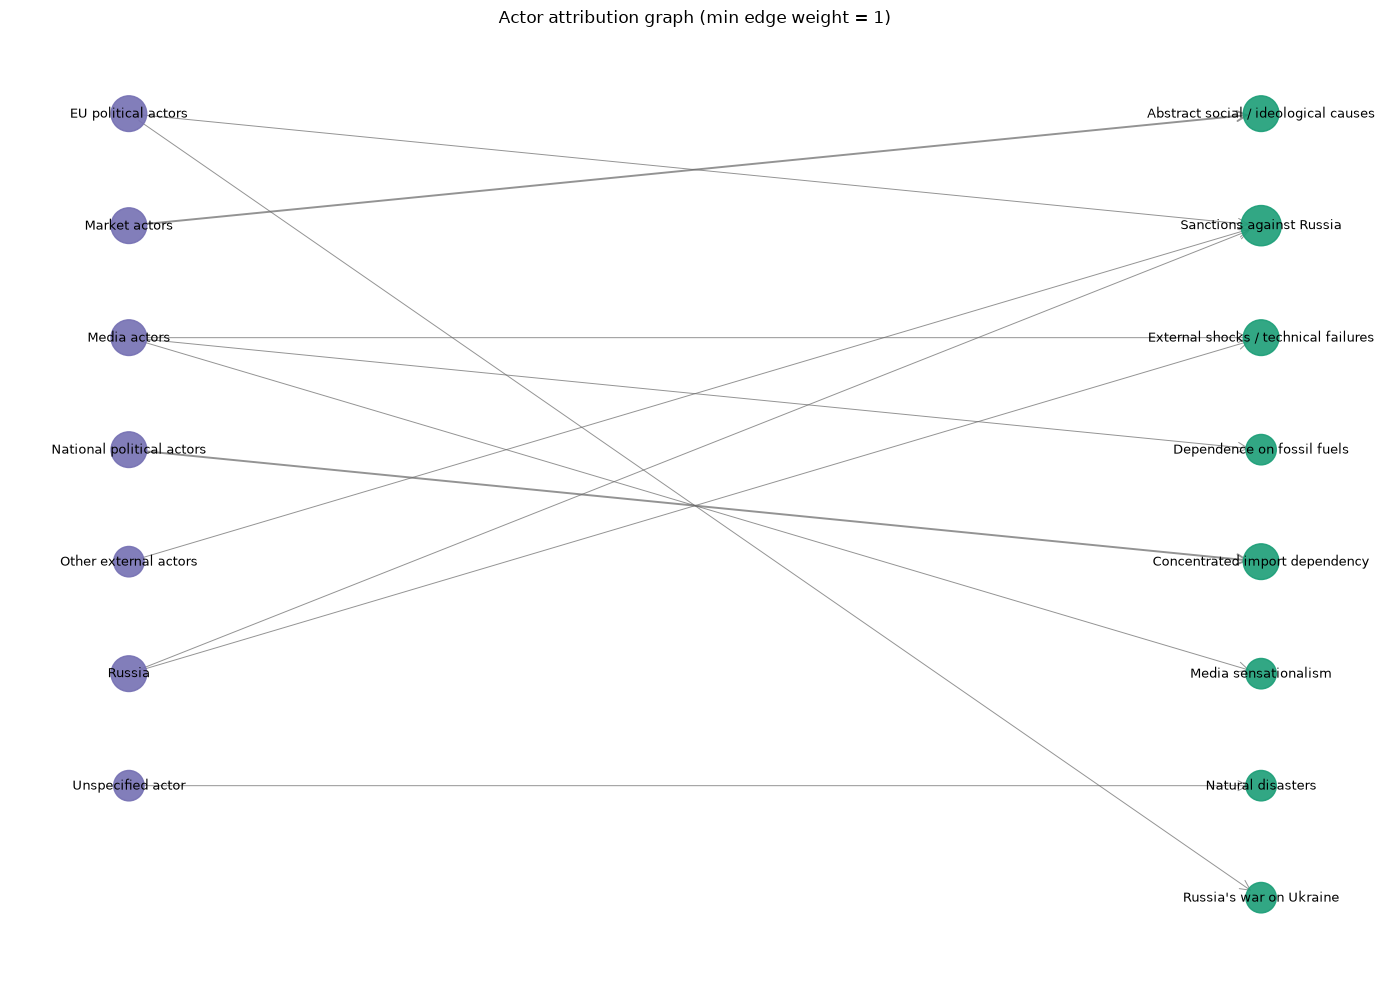

In [17]:
# -----------------------------
# 6. Example plots
# -----------------------------
causal_nlp.plot_main_graph(G_main, min_weight=1, figsize=(14, 10))
causal_nlp.plot_actor_graph(G_actor, min_weight=1, figsize=(14, 10))

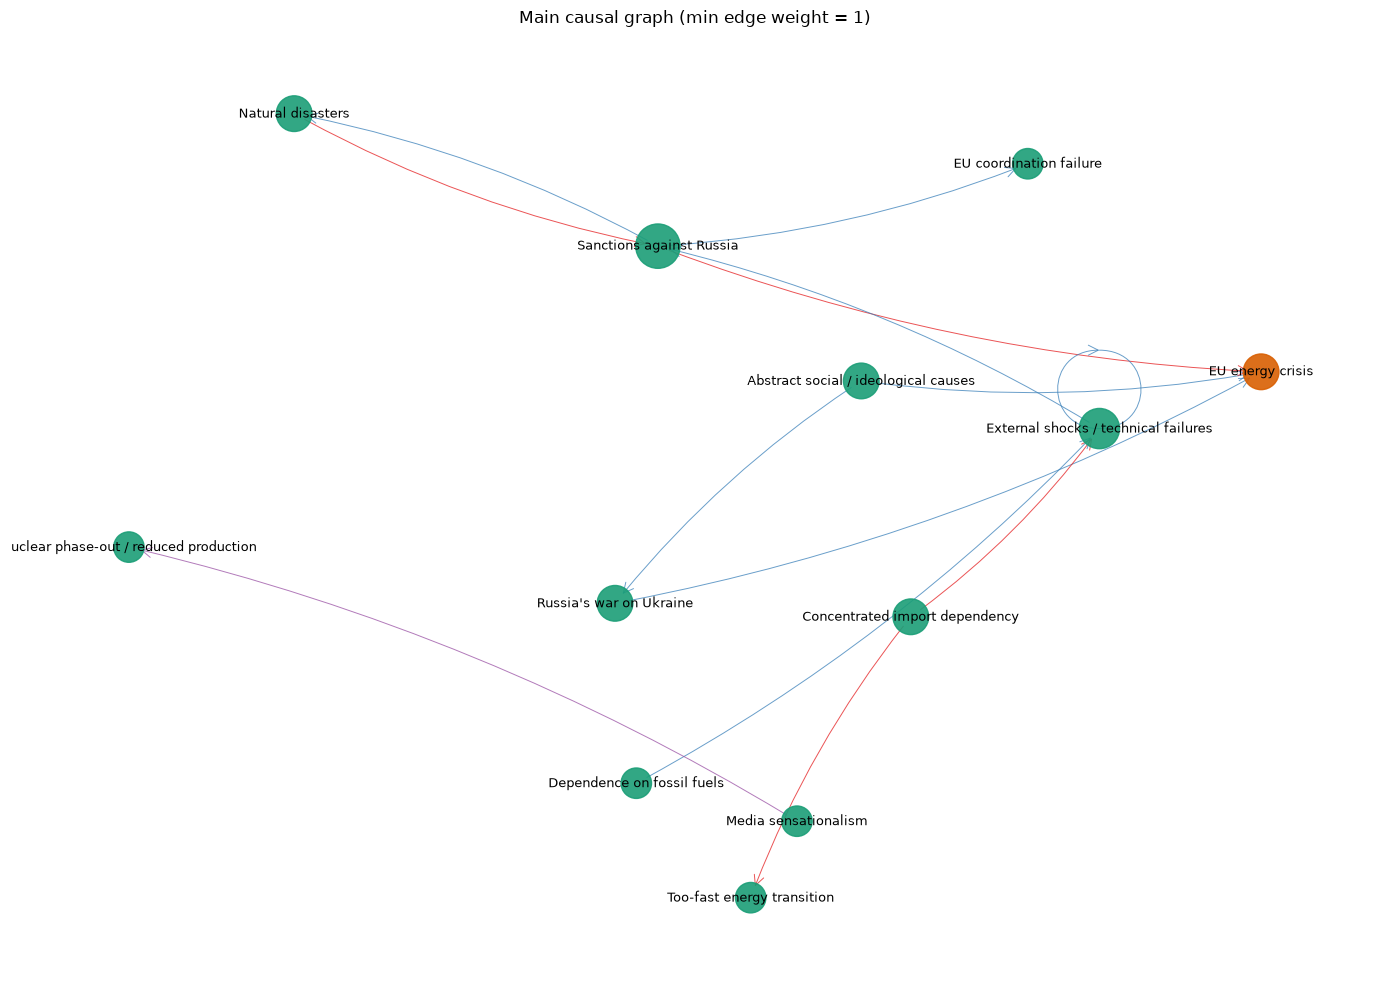

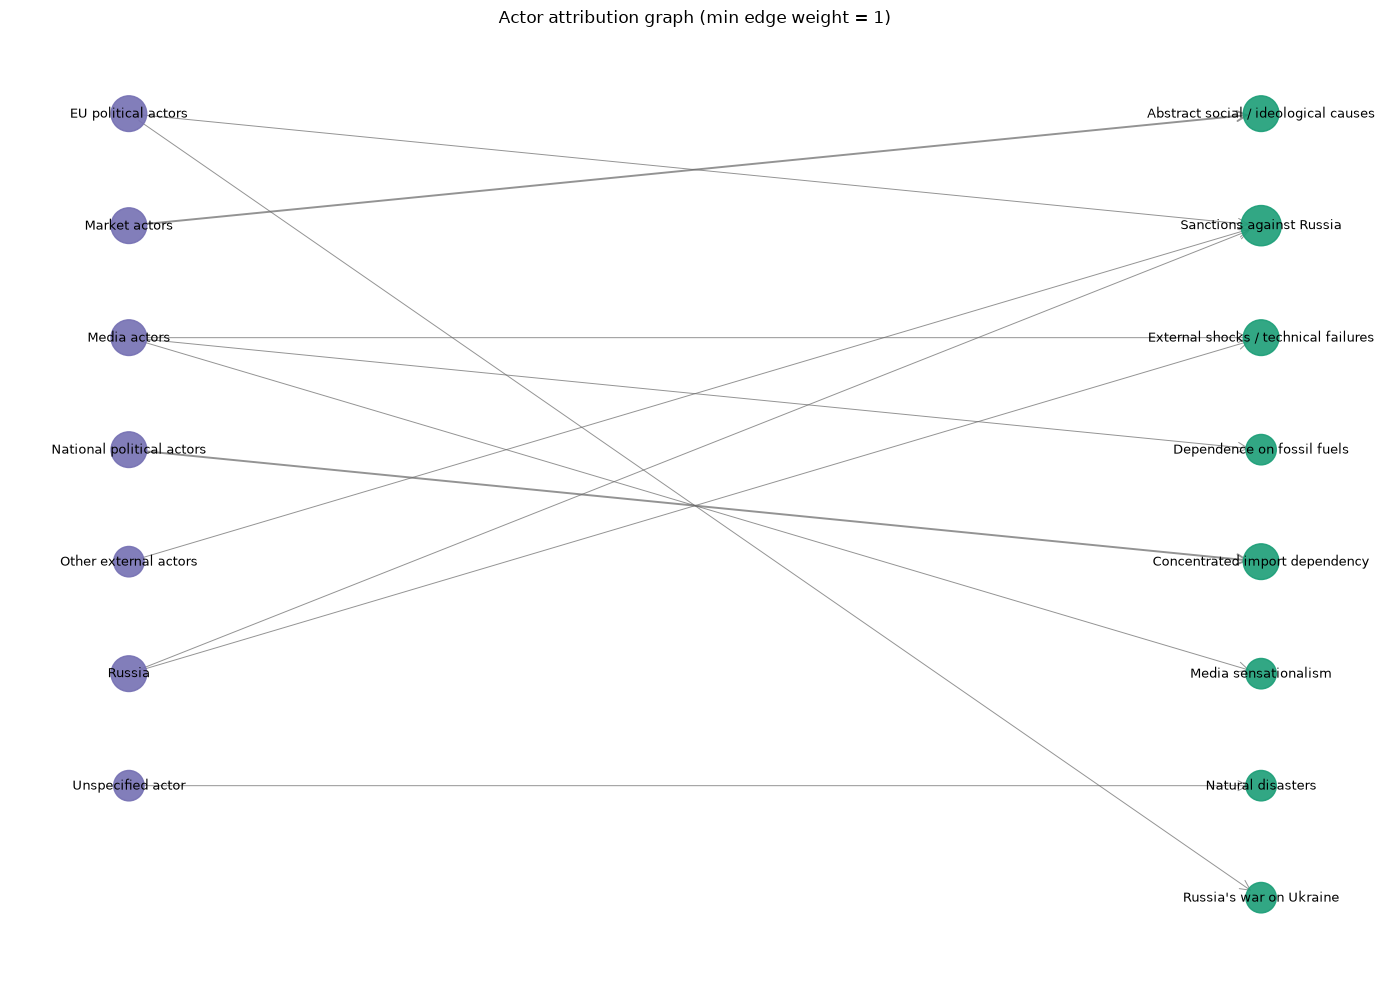

In [18]:
# -----------------------------
# 6. Example plots
# -----------------------------
causal_nlp.plot_main_graph(G_main, min_weight=1, figsize=(14, 10))
causal_nlp.plot_actor_graph(G_actor, min_weight=1, figsize=(14, 10))

# Manual Annotation

In [19]:
EDGE_TYPES = SCHEMA["schema"]["properties"]["claims"]["items"]["properties"]["edge_type"]["enum"]  # added: was not defined in the notebook
ann = df_t[["QID8", "QID8_en"]].copy().reset_index().rename(columns={"index": "response_id"})
MAX_CLAIMS=3
for i in range(1, MAX_CLAIMS + 1):
    for col in ["cause_node", "actor_attribution", "target", "edge_type", "evidence", "confidence"]:
        ann[f"claim{i}_{col}"] = ""

ann["manual_has_causal_claim"] = ""
ann["manual_notes"] = ""

ann.to_excel(f"{OUT_DIR}/manual_annotation.xlsx", index=False)

if os.path.exists(f"{DATA_DIR}/manual_annotation.xlsx"):  # added: never overwrite an existing (possibly filled) annotation sheet
    print(f"{DATA_DIR}/manual_annotation.xlsx exists - not overwritten; empty template written to {OUT_DIR}/manual_annotation.xlsx")
else:
    with pd.ExcelWriter(f"{DATA_DIR}/manual_annotation.xlsx") as writer:
        ann.to_excel(writer, sheet_name="annotate", index=False)
        pd.DataFrame({
            "CAUSE_CODES": pd.Series(CAUSE_CODES),
            "ACTOR_CODES": pd.Series(ACTOR_CODES),
            "EDGE_TYPES": pd.Series(EDGE_TYPES)
        }).to_excel(writer, sheet_name="codes", index=False)

dummy_data/manual_annotation.xlsx exists - not overwritten; empty template written to output/manual_annotation.xlsx


In [20]:
results_df = results_mode_df.reset_index()  # added: results_df was not defined in the notebook; assumed = modal LLM result per answer
manual = pd.read_excel(f"{DATA_DIR}/manual_annotation.xlsx", sheet_name="annotate")
manual["response_id"] = manual["response_id"].astype(str)
manual["manual_has_causal_claim"] = manual["manual_has_causal_claim"].astype(str).str.upper().eq("TRUE")

manual_long = pd.concat([
    manual[["response_id"]].assign(
        cause_node=manual[f"claim{i}_cause_node"],
        actor_attribution=manual[f"claim{i}_actor_attribution"],
        target=manual[f"claim{i}_target"],
        edge_type=manual[f"claim{i}_edge_type"],
        evidence=manual[f"claim{i}_evidence"],
        confidence=manual[f"claim{i}_confidence"],
    )
    for i in range(1, MAX_CLAIMS + 1)
], ignore_index=True).dropna(subset=["cause_node"], how="all")

llm_long = (
    results_df[["response_id", "has_causal_claim", "claims"]]
    .assign(response_id=lambda d: d["response_id"].astype(str))
    .explode("claims")
)
llm_long = pd.concat(
    [llm_long.drop(columns="claims").reset_index(drop=True),
     pd.json_normalize(llm_long["claims"]).reset_index(drop=True)],
    axis=1
).dropna(subset=["cause_node"], how="all")

manual_long

,response_id,cause_node,actor_attribution,target,edge_type,evidence,confidence
2,4,MARKET_SPECULATION,NATIONAL_POLITICS,FAST_TRANSITION,WORSENS,(synthetic example),low
4,6,PRICE_REGULATION_FAILURE,EU_POLITICS,EU_ENERGY_CRISIS,CAUSES,(synthetic example),low
5,7,IMPORT_CONCENTRATION,MEDIA_ACTORS,EXT_SHOCKS,CAUSES,(synthetic example),low
6,8,NUCLEAR_PHASEOUT_REDUCED_PRODUCTION,MARKET_ACTORS,WAR_UKRAINE,CAUSES,(synthetic example),high
8,10,EXT_SHOCKS,RUSSIA,EXT_SHOCKS,CAUSES,(synthetic example),high
9,11,EU_SANCTIONS_RUSSIA,EU_POLITICS,EU_COORDINATION_FAILURE,CAUSES,(synthetic example),low
12,14,ABSTRACT_SOCIAL,MARKET_ACTORS,EU_ENERGY_CRISIS,CAUSES,(synthetic example),high
13,15,NATURAL_DISASTERS,MEDIA_ACTORS,EU_SANCTIONS_RUSSIA,CAUSES,(synthetic example),high
15,17,PRICE_REGULATION_FAILURE,OTHER_EXTERNAL_ACTORS,NATURAL_DISASTERS,CAUSES,(synthetic example),high
20,6,EU_SANCTIONS_RUSSIA,RUSSIA,EU_ENERGY_CRISIS,WORSENS,(synthetic example),high


In [21]:
claim_eval = manual[["response_id", "manual_has_causal_claim"]].merge(
    results_df[["response_id", "has_causal_claim"]].assign(
        response_id=lambda d: d["response_id"].astype(str),
        has_causal_claim=lambda d: d["has_causal_claim"].astype("boolean")
    ),
    on="response_id",
    how="left"
)
claim_eval["has_causal_claim"] = claim_eval["has_causal_claim"].fillna(False).astype(bool)

manual_nodes = manual_long.groupby("response_id")["cause_node"].apply(lambda s: set(s.dropna()))
llm_nodes = llm_long.groupby("response_id")["cause_node"].apply(lambda s: set(s.dropna()))

node_compare = pd.DataFrame({"manual": manual_nodes, "llm": llm_nodes}).fillna("").reset_index()

manual_edges = (
    manual_long.assign(edge=list(zip(manual_long["cause_node"], manual_long["target"])))
    .groupby("response_id")["edge"]
    .apply(set)
)

llm_edges = (
    llm_long.assign(edge=list(zip(llm_long["cause_node"], llm_long["target"])))
    .groupby("response_id")["edge"]
    .apply(set)
)

edge_compare = pd.DataFrame({"manual": manual_edges, "llm": llm_edges}).fillna("").reset_index()

In [22]:
node_compare

,response_id,manual,llm
0,10,{EXT_SHOCKS},{EXT_SHOCKS}
1,11,"{MARKET_SPECULATION, EU_SANCTIONS_RUSSIA}","{NATURAL_DISASTERS, EU_SANCTIONS_RUSSIA}"
2,14,{ABSTRACT_SOCIAL},{ABSTRACT_SOCIAL}
3,15,"{NATURAL_DISASTERS, NUCLEAR_PHASEOUT_REDUCED_PRODUCTION}","{IMPORT_CONCENTRATION, EXT_SHOCKS}"
4,17,{PRICE_REGULATION_FAILURE},{EU_SANCTIONS_RUSSIA}
5,4,{MARKET_SPECULATION},{IMPORT_CONCENTRATION}
6,6,"{EU_SANCTIONS_RUSSIA, PRICE_REGULATION_FAILURE}","{WAR_UKRAINE, EU_SANCTIONS_RUSSIA}"
7,7,"{MEDIA_SENSATIONALISM, IMPORT_CONCENTRATION}","{MEDIA_SENSATIONALISM, FOSSIL_DEPENDENCE}"
8,8,{NUCLEAR_PHASEOUT_REDUCED_PRODUCTION},{ABSTRACT_SOCIAL}
